In [5]:
import inspect
import numpy as np
import pandas as pd
from pathlib import Path

# Check the current working state.
print("Current directory:", Path.cwd())
print("raw exists:", "raw" in globals())
print("epoch_table exists:", "epoch_table" in globals())
print(
    "detector exists:",
    "detect_spindles_in_epoch" in globals()
)

# Inspect the detector we are actually running.
if "detect_spindles_in_epoch" in globals():
    print("\nDetector signature:")
    print(inspect.signature(detect_spindles_in_epoch))

    print("\nDetector source:")
    print(inspect.getsource(detect_spindles_in_epoch))

# Check recording metadata if the objects are present.
if "raw" in globals():
    print("\nSampling frequency:", raw.info["sfreq"])
    print("Channels:", raw.ch_names)

if "epoch_table" in globals():
    print("\nEpoch table shape:", epoch_table.shape)
    print("Columns:", epoch_table.columns.tolist())
    print("\nStage distribution:")
    print(epoch_table["stage"].value_counts())


Current directory: d:\sscp\notebooks
raw exists: True
epoch_table exists: True
detector exists: True

Detector signature:
(signal, sfreq, threshold_sd=1.5, min_duration=0.5, max_duration=2.0, merge_gap=0.1)

Detector source:
def detect_spindles_in_epoch(
    signal,
    sfreq,
    threshold_sd=1.5,
    min_duration=0.5,
    max_duration=2.0,
    merge_gap=0.1,
):
    signal = np.asarray(signal, dtype=float)

    if signal.ndim != 1 or len(signal) < 10:
        raise ValueError("signal must be a 1D array with enough samples.")
    if not np.isfinite(signal).all():
        raise ValueError("Signal contains non-finite values.")

    sos = butter(
        4, [11, 16],
        btype="bandpass",
        fs=sfreq,
        output="sos",
    )
    filtered = sosfiltfilt(sos, signal)
    envelope = np.abs(hilbert(filtered))

    smooth_samples = max(1, int(round(0.1 * sfreq)))
    envelope = uniform_filter1d(envelope, size=smooth_samples)

    threshold = envelope.mean() + threshold_sd * envelop

In [7]:

from pathlib import Path
import sys
import pandas as pd

# 1. Resolve the project root.
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (project_root / "src").is_dir(), f"src folder not found: {project_root / 'src'}"

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)

# 2. Import the existing project functions.
from src.data_loader import load_recording
from src.preprocessing import build_epoch_table

# 3. Find and pair the PSG and hypnogram files.
cassette_dir = project_root / "data" / "raw" / "sleep-cassette"

psg_files = sorted(cassette_dir.glob("*-PSG.edf"))
hyp_files = sorted(cassette_dir.glob("*-Hypnogram.edf"))

hyp_map = {p.name[:6]: p for p in hyp_files}

recording_pairs = [
    (psg, hyp_map[psg.name[:6]])
    for psg in psg_files
    if psg.name[:6] in hyp_map
]

print("Matched recordings:", len(recording_pairs))

# 4. Load the same example recording used in the handoff.
target_id = "SC4001E0"

matches = [
    (psg, hyp)
    for psg, hyp in recording_pairs
    if psg.stem.replace("-PSG", "") == target_id
]

if not matches:
    raise FileNotFoundError(
        f"{target_id} was not found in {cassette_dir}. "
        "Check the dataset location and recording filenames."
    )

PSG_PATH, HYPNOGRAM_PATH = matches[0]

raw = load_recording(PSG_PATH, HYPNOGRAM_PATH)
epoch_table = build_epoch_table(raw, epoch_seconds=30)

# 5. Verify the restored state.
print("\nPSG:", PSG_PATH.name)
print("Hypnogram:", HYPNOGRAM_PATH.name)
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Epoch table shape:", epoch_table.shape)
print("Columns:", epoch_table.columns.tolist())
print("\nStage counts:")
print(epoch_table["stage"].value_counts().sort_index())


Project root: d:\sscp
Matched recordings: 153


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)



PSG: SC4001E0-PSG.edf
Hypnogram: SC4001EC-Hypnogram.edf
Sampling frequency: 100.0 Hz
Epoch table shape: (2650, 4)
Columns: ['epoch_index', 'start_sec', 'end_sec', 'stage']

Stage counts:
stage
N1       58
N2      250
N3      220
REM     125
W      1997
Name: count, dtype: int64


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import uniform_filter1d

# Restore the original experimental detector from the handoff.
def detect_spindles_in_epoch(
    signal,
    sfreq,
    threshold_sd=1.5,
    min_duration=0.5,
    max_duration=2.0,
    merge_gap=0.1,
):
    signal = np.asarray(signal, dtype=float)

    if signal.ndim != 1 or len(signal) < 10:
        raise ValueError("signal must be a 1D array with enough samples.")
    if not np.isfinite(signal).all():
        raise ValueError("Signal contains non-finite values.")

    sos = butter(
        4, [11, 16],
        btype="bandpass",
        fs=sfreq,
        output="sos",
    )
    filtered = sosfiltfilt(sos, signal)
    envelope = np.abs(hilbert(filtered))

    smooth_samples = max(1, int(round(0.1 * sfreq)))
    envelope = uniform_filter1d(envelope, size=smooth_samples)

    threshold = envelope.mean() + threshold_sd * envelope.std()
    active = envelope > threshold

    # Bridge gaps of up to merge_gap seconds.
    max_gap_samples = int(round(merge_gap * sfreq))
    active_indices = np.flatnonzero(active)
    events = []

    if len(active_indices):
        groups = np.split(
            active_indices,
            np.where(
                np.diff(active_indices) > max_gap_samples + 1
            )[0] + 1,
        )

        for group in groups:
            start = int(group[0])
            end = int(group[-1]) + 1
            duration = (end - start) / sfreq

            if min_duration <= duration <= max_duration:
                events.append({
                    "start_sec": start / sfreq,
                    "end_sec": end / sfreq,
                    "duration_sec": duration,
                    "peak_envelope": float(envelope[start:end].max()),
                })

    return events, filtered, envelope, threshold


# Reproducible sample design.
SEED = 42
TARGET_PER_STAGE = 20
STAGES = ["W", "N1", "N2", "N3", "REM"]
rng = np.random.default_rng(SEED)

# Shuffle recording order without changing the original list.
order = rng.permutation(len(recording_pairs))

sampled_epochs = []
seen_subject_stage = set()

for idx in order:
    psg_path, hyp_path = recording_pairs[idx]
    subject_id = psg_path.name[:5]
    recording_id = psg_path.stem.replace("-PSG", "")

    # Skip a subject if all five stages have already been sampled.
    missing_stages = [
        stage for stage in STAGES
        if (subject_id, stage) not in seen_subject_stage
    ]
    if not missing_stages:
        continue

    try:
        recording_raw = load_recording(psg_path, hyp_path)
        table = build_epoch_table(recording_raw, epoch_seconds=30)

        # Pick at most one epoch per subject per stage.
        for stage in missing_stages:
            candidates = table.index[table["stage"] == stage].to_numpy()

            if len(candidates) == 0:
                continue

            # Prefer reproducible random selection within the recording.
            row_idx = int(rng.choice(candidates))
            row = table.loc[row_idx]

            sampled_epochs.append({
                "subject_id": subject_id,
                "recording_id": recording_id,
                "epoch_index": int(row["epoch_index"]),
                "start_sec": float(row["start_sec"]),
                "end_sec": float(row["end_sec"]),
                "stage": stage,
            })
            seen_subject_stage.add((subject_id, stage))

        recording_raw.close()

    except Exception as exc:
        print(f"Skipped {recording_id}: {type(exc).__name__}: {exc}")
        continue

    counts = pd.Series(
        [r["stage"] for r in sampled_epochs]
    ).value_counts()

    if all(counts.get(s, 0) >= TARGET_PER_STAGE for s in STAGES):
        break

sample_df = pd.DataFrame(sampled_epochs)

if sample_df.empty:
    raise RuntimeError("No epochs were sampled. Check the recording loader.")

print("Sampled epochs by stage:")
print(sample_df["stage"].value_counts().reindex(STAGES, fill_value=0))

print("\nUnique subjects by stage:")
print(sample_df.groupby("stage")["subject_id"].nunique().reindex(STAGES))

print("\nUnique subjects overall:", sample_df["subject_id"].nunique())
print("Unique recordings overall:", sample_df["recording_id"].nunique())

# Report whether we reached the target.
stage_counts = sample_df["stage"].value_counts()
print("\nTarget reached for every stage:",
      all(stage_counts.get(s, 0) >= TARGET_PER_STAGE for s in STAGES))


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:2

Sampled epochs by stage:
stage
W      23
N1     23
N2     23
N3     20
REM    23
Name: count, dtype: int64

Unique subjects by stage:
stage
W      23
N1     23
N2     23
N3     20
REM    23
Name: subject_id, dtype: int64

Unique subjects overall: 23
Unique recordings overall: 23

Target reached for every stage: True


In [8]:

import numpy as np
import pandas as pd
from pathlib import Path

EVALUATION_CHANNEL = "EEG Fpz-Cz"

epoch_results = []
candidate_results = []

# Process all sampled epochs from a recording while loading that recording only once.
for recording_id, recording_samples in sample_df.groupby("recording_id"):
    pair = next(
        (p for p in recording_pairs
         if Path(p[0]).stem.replace("-PSG", "") == recording_id),
        None
    )

    if pair is None:
        print(f"Skipping {recording_id}: matching recording pair not found.")
        continue

    psg_path, hypnogram_path = pair
    raw = None

    try:
        raw = load_recording(psg_path, hypnogram_path)

        if EVALUATION_CHANNEL not in raw.ch_names:
            print(f"Skipping {recording_id}: {EVALUATION_CHANNEL} unavailable.")
            continue

        sfreq = raw.info["sfreq"]
        signal = raw.get_data(picks=[EVALUATION_CHANNEL])[0]

        for _, epoch in recording_samples.iterrows():
            start_sample = int(round(epoch["start_sec"] * sfreq))
            end_sample = int(round(epoch["end_sec"] * sfreq))
            epoch_signal = signal[start_sample:end_sample]

            if len(epoch_signal) < int(29 * sfreq):
                print(
                    f"Skipping short epoch: {recording_id}, "
                    f"epoch {epoch['epoch_index']}"
                )
                continue

            events, filtered, envelope, threshold = detect_spindles_in_epoch(
                epoch_signal, sfreq
            )

            epoch_results.append({
                "subject_id": epoch["subject_id"],
                "recording_id": recording_id,
                "epoch_index": epoch["epoch_index"],
                "stage": epoch["stage"],
                "n_candidates": len(events),
                "threshold": threshold,
                "epoch_duration_sec": len(epoch_signal) / sfreq,
            })

            for event_number, event in enumerate(events, start=1):
                candidate_results.append({
                    "subject_id": epoch["subject_id"],
                    "recording_id": recording_id,
                    "epoch_index": epoch["epoch_index"],
                    "stage": epoch["stage"],
                    "event_number": event_number,
                    "start_in_epoch_sec": event["start_sec"],
                    "end_in_epoch_sec": event["end_sec"],
                    "duration_sec": event["duration_sec"],
                    "peak_envelope": event["peak_envelope"],
                    "threshold": threshold,
                })

    except Exception as exc:
        print(f"Error processing {recording_id}: {type(exc).__name__}: {exc}")

    finally:
        if raw is not None:
            raw.close()

sample_detection_df = pd.DataFrame(epoch_results)
candidate_events_df = pd.DataFrame(candidate_results)

print("Successfully evaluated epochs:", len(sample_detection_df))
print("Candidate events detected:", len(candidate_events_df))

print("\nEpoch-level summary by stage:")
display(
    sample_detection_df.groupby("stage").agg(
        epochs=("epoch_index", "size"),
        mean_candidates=("n_candidates", "mean"),
        median_candidates=("n_candidates", "median"),
        epochs_with_candidates=(
            "n_candidates", lambda x: (x > 0).sum()
        ),
        zero_candidate_epochs=(
            "n_candidates", lambda x: (x == 0).sum()
        ),
    ).round(3).reindex(["W", "N1", "N2", "N3", "REM"])
)

print("\nCandidate duration summary by stage:")
if not candidate_events_df.empty:
    display(
        candidate_events_df.groupby("stage")["duration_sec"].agg(
            ["count", "mean", "median", "min", "max"]
        ).round(3).reindex(["W", "N1", "N2", "N3", "REM"])
    )
else:
    print("No candidates detected in the sample.")

print("\nNumber of evaluated epochs per stage:")
print(sample_detection_df["stage"].value_counts())


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:2

Successfully evaluated epochs: 112
Candidate events detected: 76

Epoch-level summary by stage:


,epochs,mean_candidates,median_candidates,epochs_with_candidates,zero_candidate_epochs
stage,,,,,
W,23,0.348,0.0,6,17
N1,23,1.087,1.0,16,7
N2,23,1.174,1.0,19,4
N3,20,0.450,0.0,7,13
REM,23,0.304,0.0,6,17



Candidate duration summary by stage:


,count,mean,median,min,max
stage,,,,,
W,8,0.734,0.59,0.51,1.85
N1,25,0.662,0.59,0.50,1.18
N2,27,0.701,0.62,0.51,1.20
N3,9,0.587,0.54,0.50,0.73
REM,7,0.643,0.59,0.53,0.97



Number of evaluated epochs per stage:
stage
W      23
N1     23
N2     23
REM    23
N3     20
Name: count, dtype: int64


In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Choose one detected epoch and one zero-candidate epoch
# for each of the four main comparison stages.
stages_to_inspect = ["N2", "N1", "W", "REM"]
chosen_epochs = []

for stage in stages_to_inspect:
    stage_rows = sample_detection_df[
        sample_detection_df["stage"] == stage
    ]

    detected = stage_rows[stage_rows["n_candidates"] > 0]
    undetected = stage_rows[stage_rows["n_candidates"] == 0]

    if not detected.empty:
        chosen_epochs.append(detected.iloc[0])

    if not undetected.empty:
        chosen_epochs.append(undetected.iloc[0])

print("Selected epochs:")
display(pd.DataFrame(chosen_epochs)[
    ["stage", "subject_id", "recording_id", "epoch_index", "n_candidates"]
])


Selected epochs:


,stage,subject_id,recording_id,epoch_index,n_candidates
2,N2,SC401,SC4012E0,1404,1
37,N2,SC426,SC4261F0,1333,0
1,N1,SC401,SC4012E0,1206,1
36,N1,SC426,SC4261F0,1523,0
30,W,SC419,SC4191E0,688,1
0,W,SC401,SC4012E0,503,0
24,REM,SC412,SC4121E0,1531,1
4,REM,SC401,SC4012E0,1136,0


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


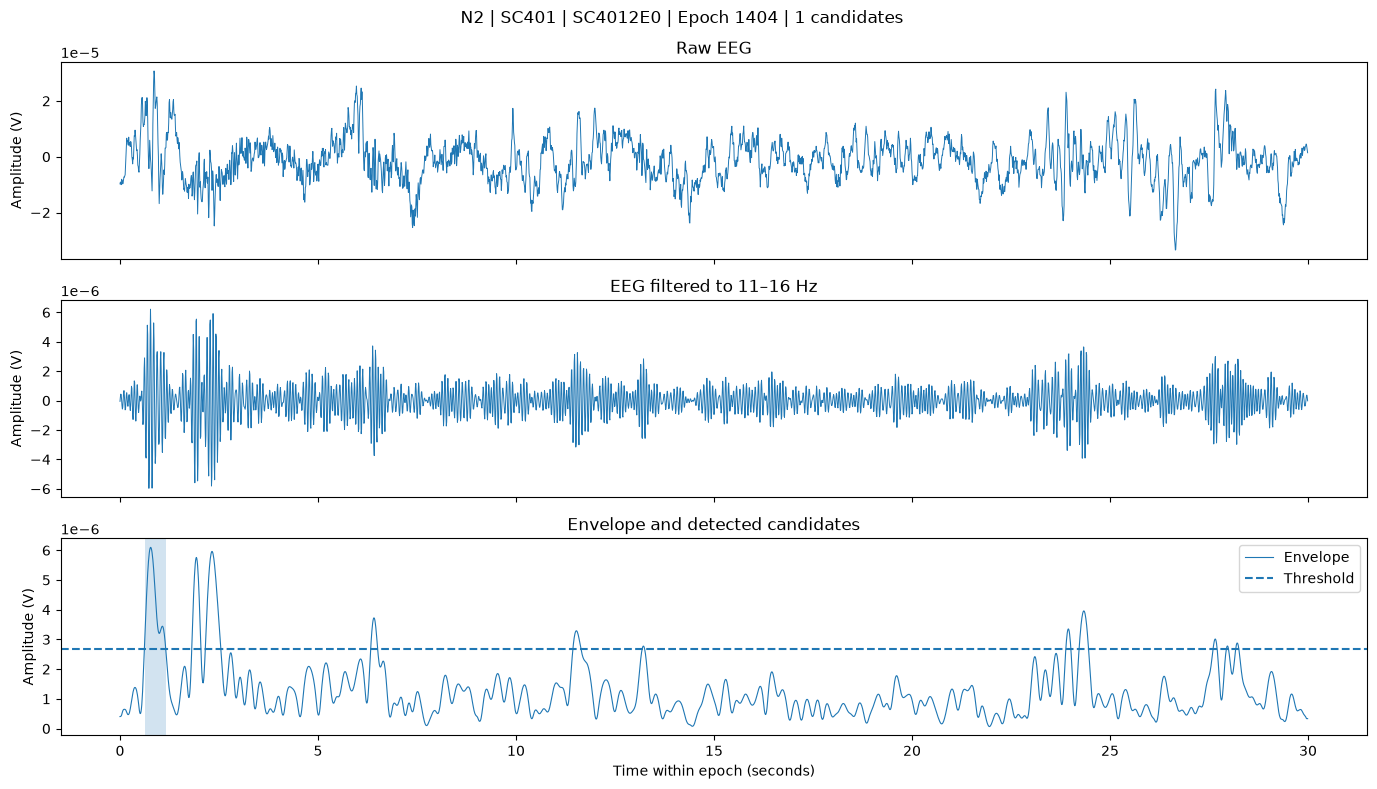

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


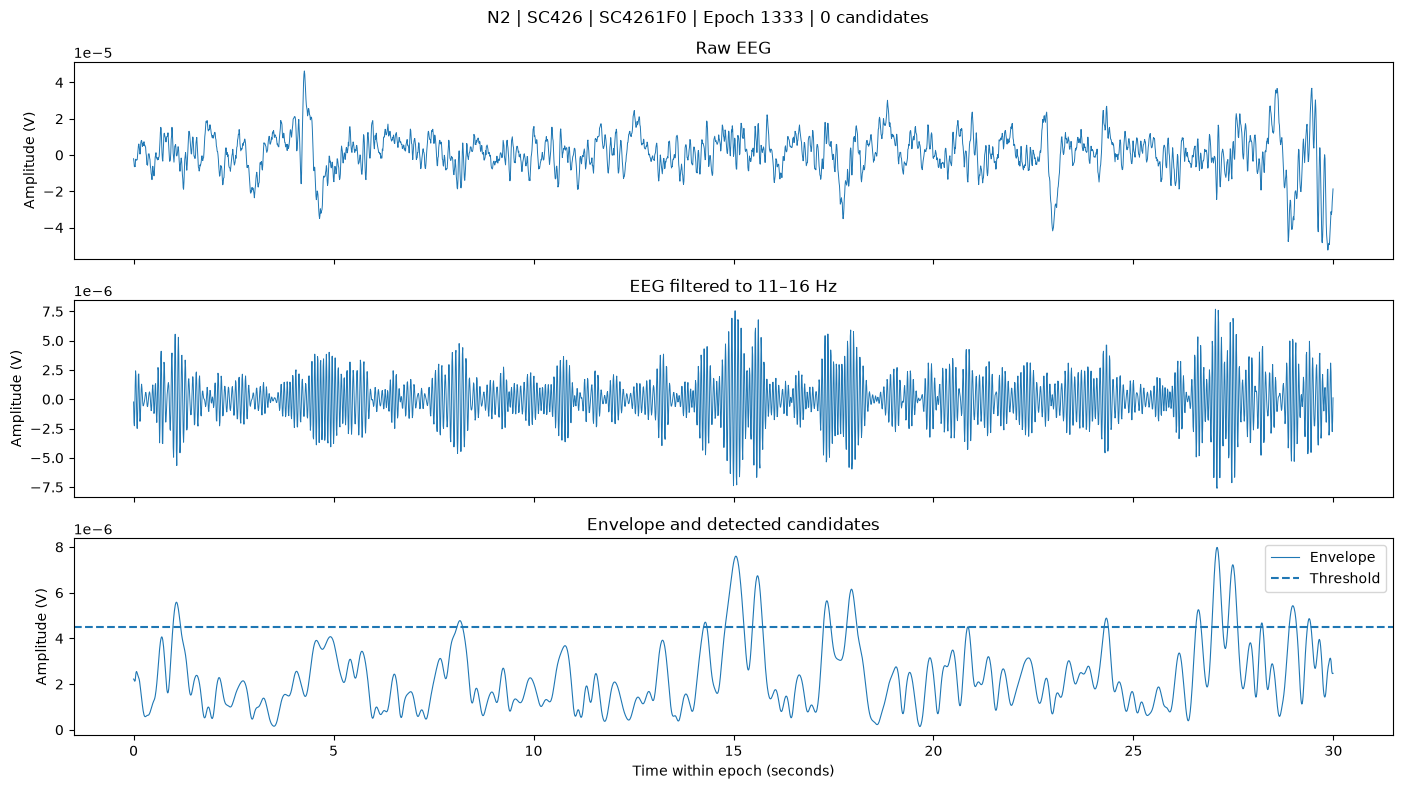

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


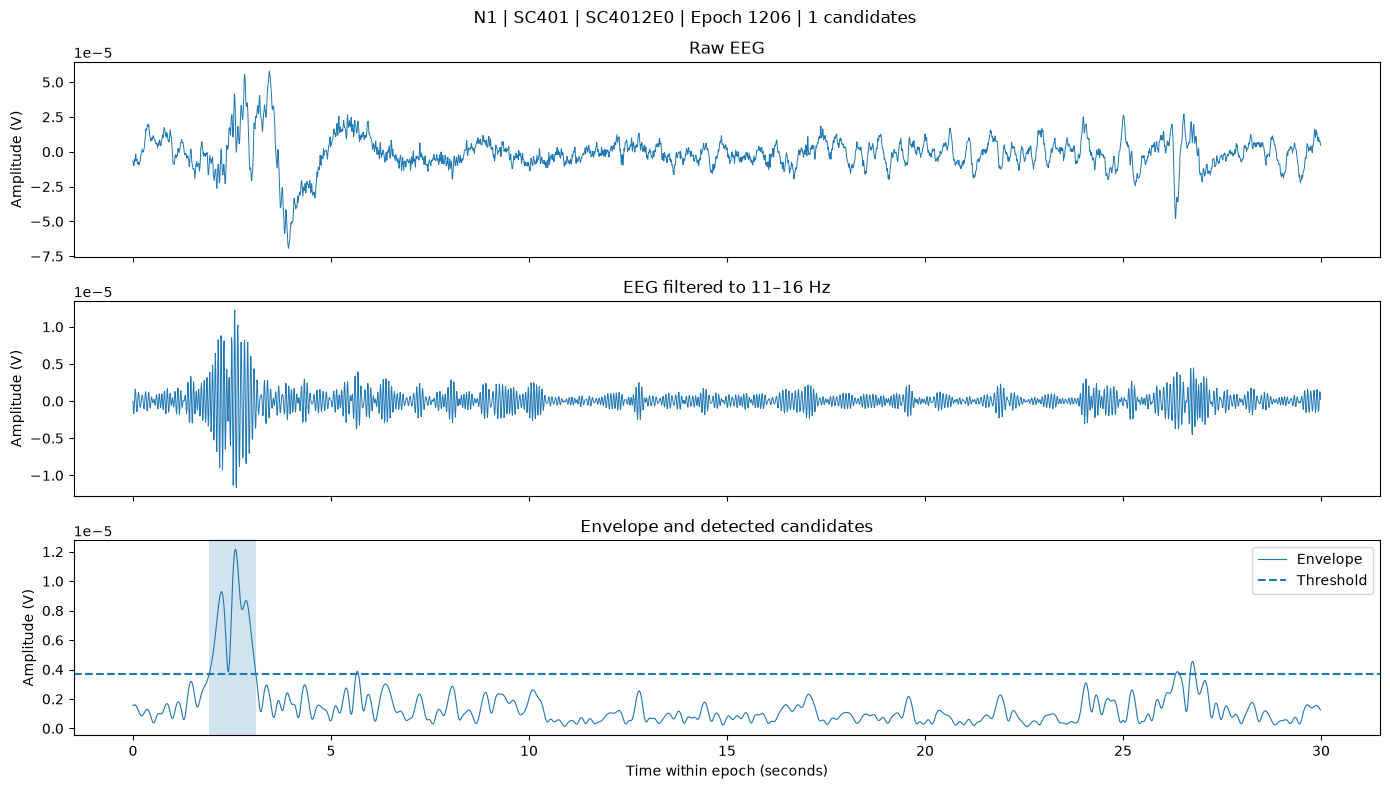

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


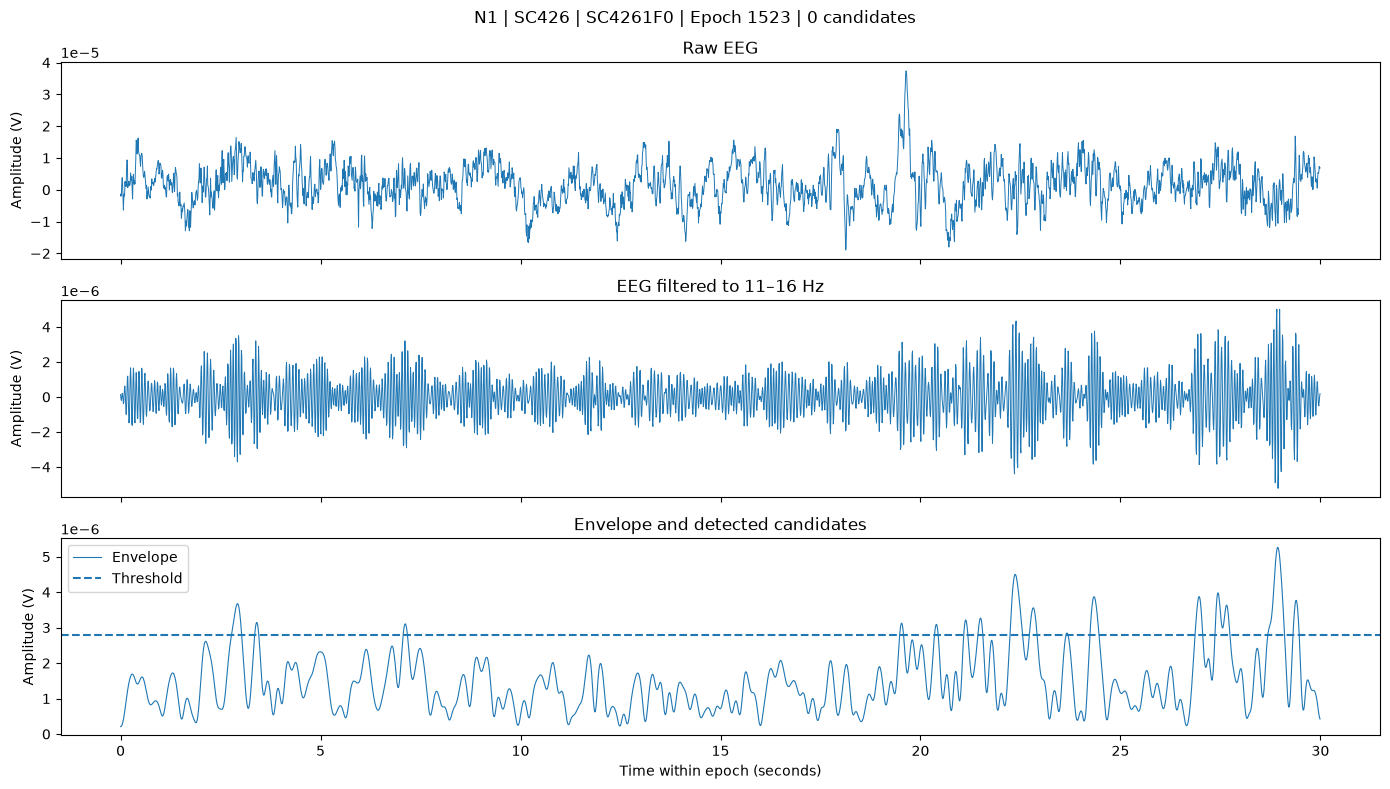

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


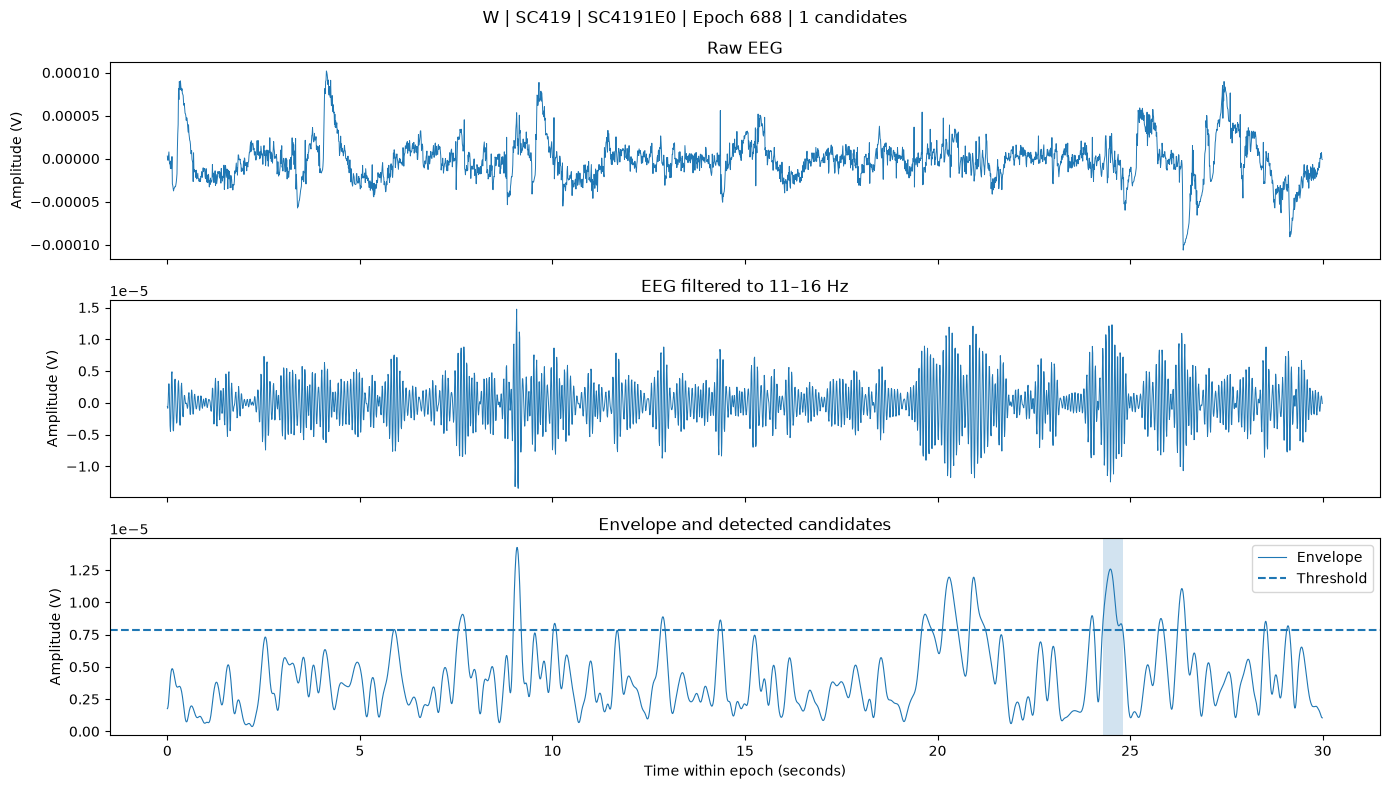

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


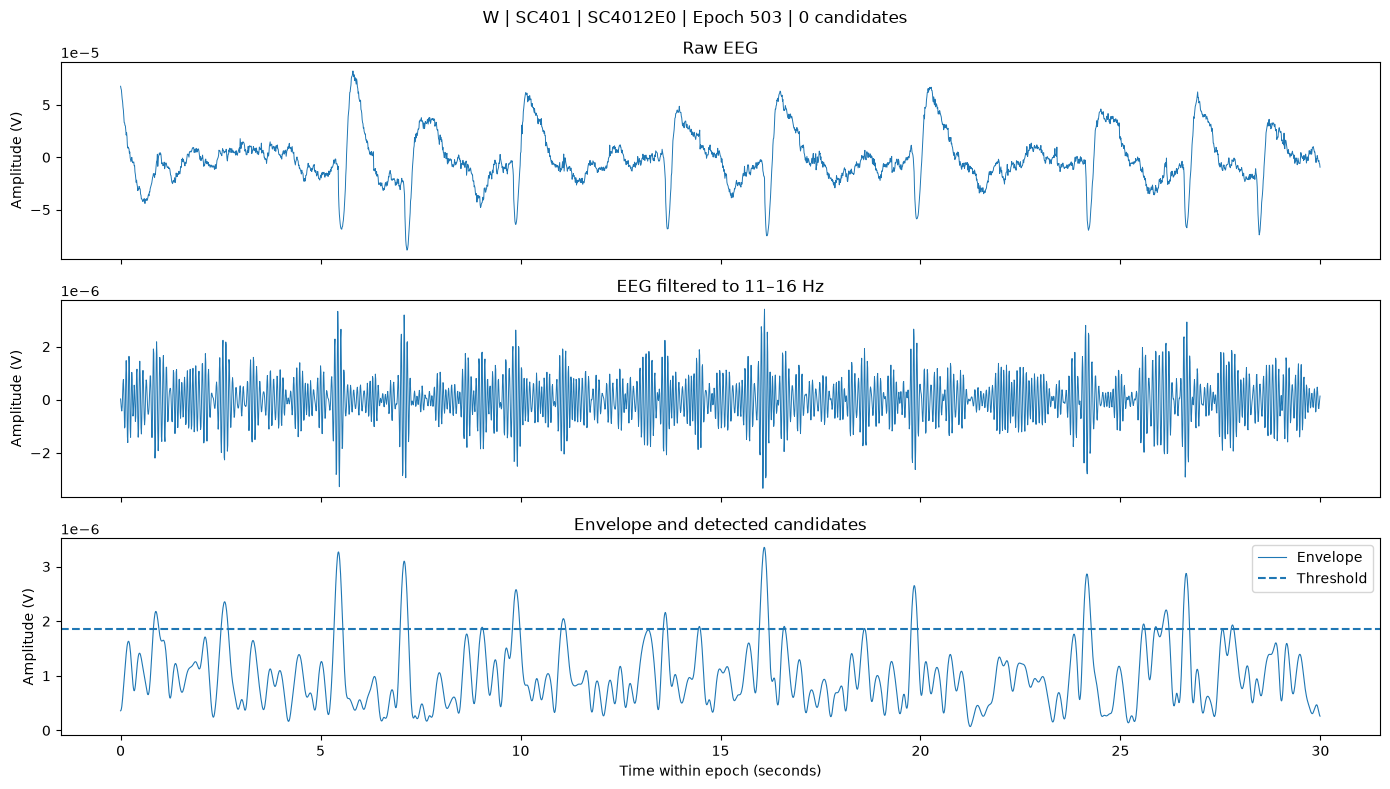

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


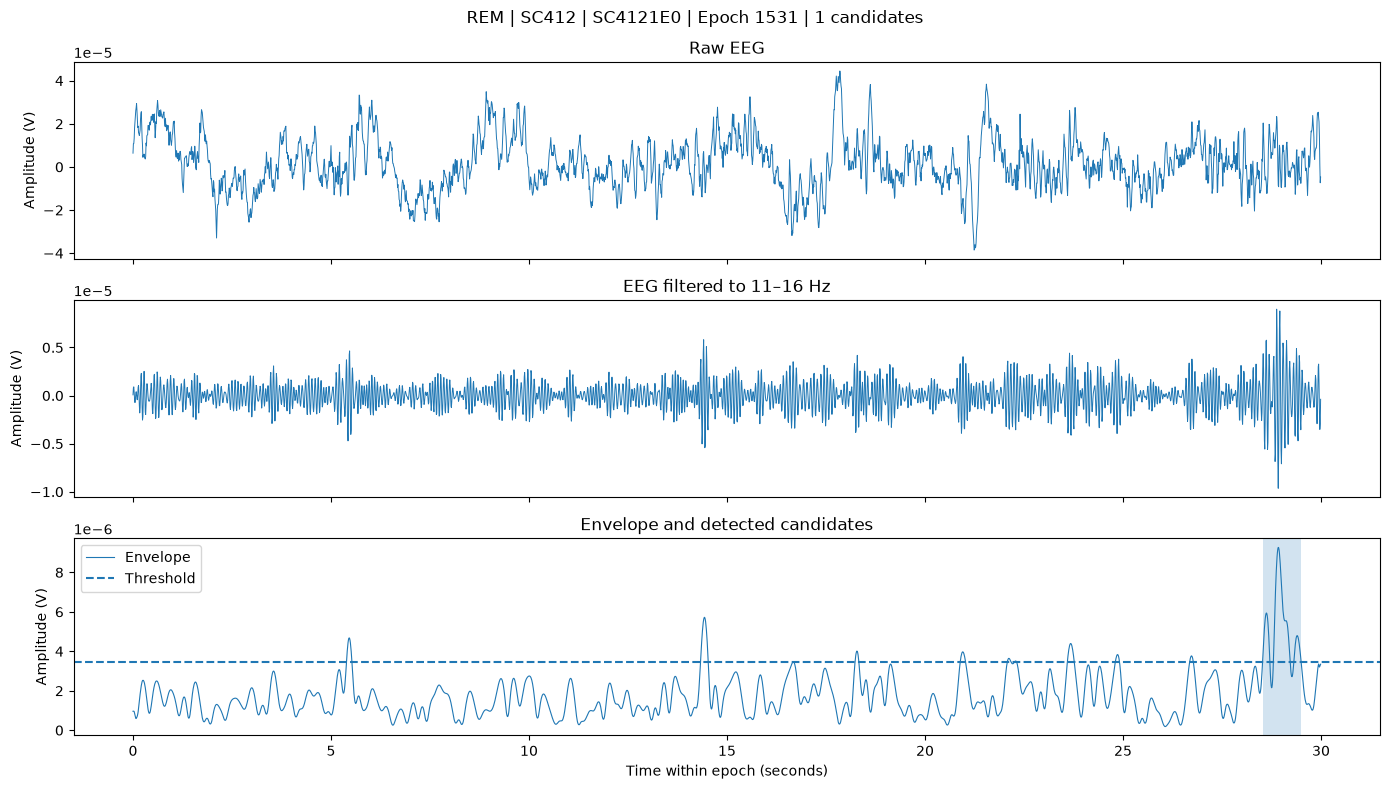

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


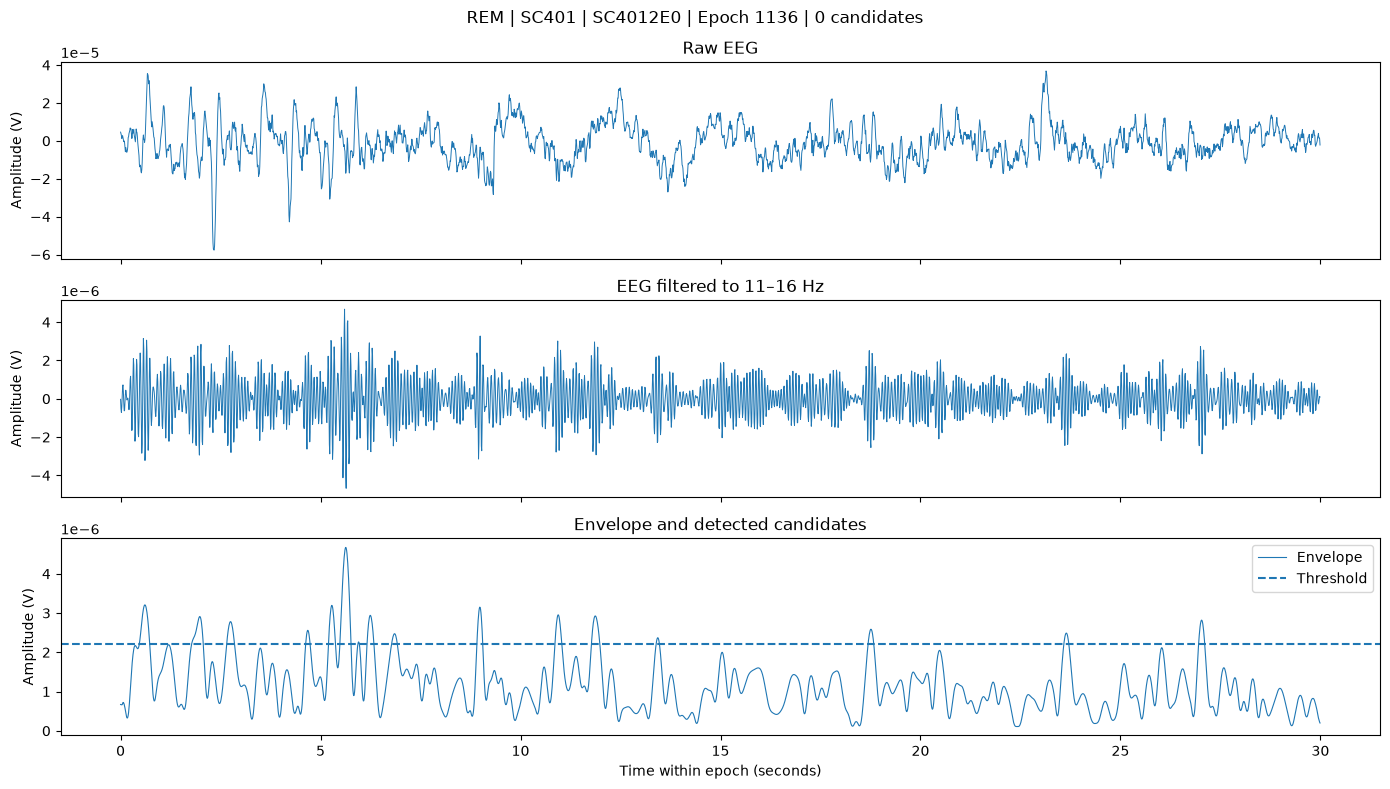

In [11]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

CHANNEL = "EEG Fpz-Cz"

# Recover epoch timing from the original sample table.
chosen_df = pd.DataFrame(chosen_epochs)

chosen_df = chosen_df.merge(
    sample_df[
        ["recording_id", "epoch_index", "start_sec", "end_sec"]
    ].drop_duplicates(),
    on=["recording_id", "epoch_index"],
    how="left",
    validate="one_to_one"
)

assert chosen_df["start_sec"].notna().all(), (
    "Some selected epochs could not be matched to their timings."
)

def find_recording_pair(recording_id):
    for psg_path, hypnogram_path in recording_pairs:
        rid = Path(psg_path).stem.replace("-PSG", "")
        if rid == recording_id:
            return psg_path, hypnogram_path
    raise FileNotFoundError(f"No recording pair found for {recording_id}")


for _, epoch in chosen_df.iterrows():
    psg_path, hypnogram_path = find_recording_pair(
        epoch["recording_id"]
    )

    raw = None
    try:
        raw = load_recording(psg_path, hypnogram_path)

        if CHANNEL not in raw.ch_names:
            print(f"Missing channel {CHANNEL}: {epoch['recording_id']}")
            continue

        sfreq = raw.info["sfreq"]
        start_sample = int(round(epoch["start_sec"] * sfreq))
        end_sample = int(round(epoch["end_sec"] * sfreq))

        raw_signal = raw.get_data(
            picks=[CHANNEL],
            start=start_sample,
            stop=end_sample
        )[0]

        events, filtered, envelope, threshold = detect_spindles_in_epoch(
            raw_signal, sfreq
        )

        time = np.arange(len(raw_signal)) / sfreq

        fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

        axes[0].plot(time, raw_signal, linewidth=0.7)
        axes[0].set_title("Raw EEG")
        axes[0].set_ylabel("Amplitude (V)")

        axes[1].plot(time, filtered, linewidth=0.7)
        axes[1].set_title("EEG filtered to 11–16 Hz")
        axes[1].set_ylabel("Amplitude (V)")

        axes[2].plot(time, envelope, linewidth=0.8, label="Envelope")
        axes[2].axhline(
            threshold, linestyle="--", label="Threshold"
        )

        for event in events:
            axes[2].axvspan(
                event["start_sec"], event["end_sec"], alpha=0.2
            )

        axes[2].set_title("Envelope and detected candidates")
        axes[2].set_xlabel("Time within epoch (seconds)")
        axes[2].set_ylabel("Amplitude (V)")
        axes[2].legend()

        fig.suptitle(
            f"{epoch['stage']} | {epoch['subject_id']} | "
            f"{epoch['recording_id']} | Epoch {int(epoch['epoch_index'])} | "
            f"{len(events)} candidates"
        )
        plt.tight_layout()
        plt.show()

    finally:
        if raw is not None:
            raw.close()


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


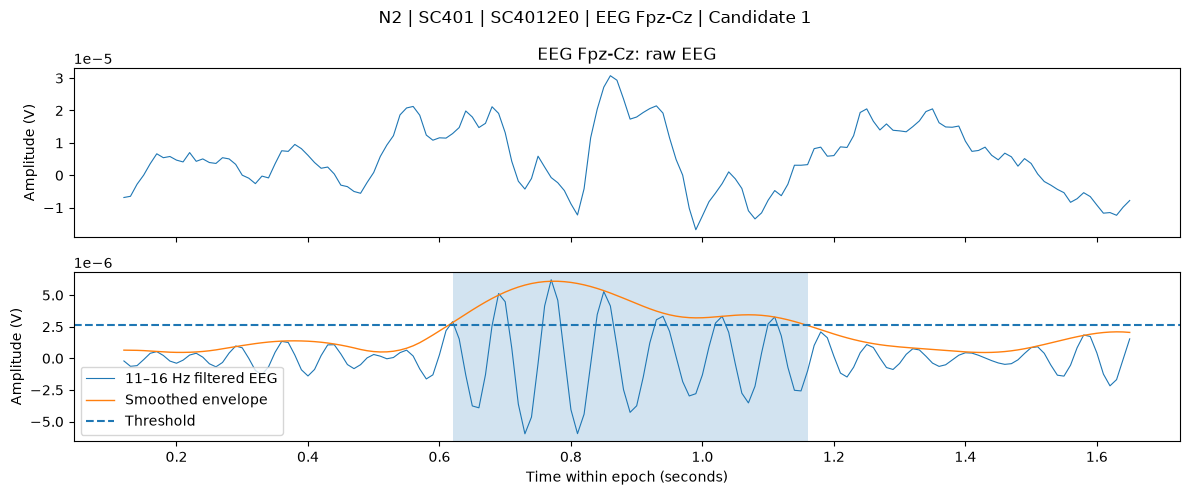

N2 | SC4012E0 | EEG Pz-Oz: no candidate in this channel


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


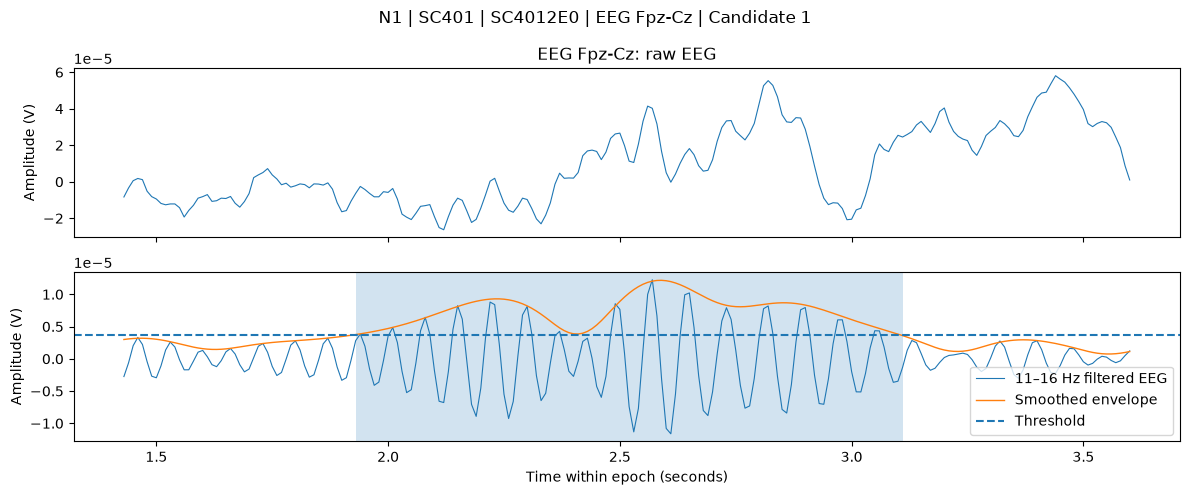

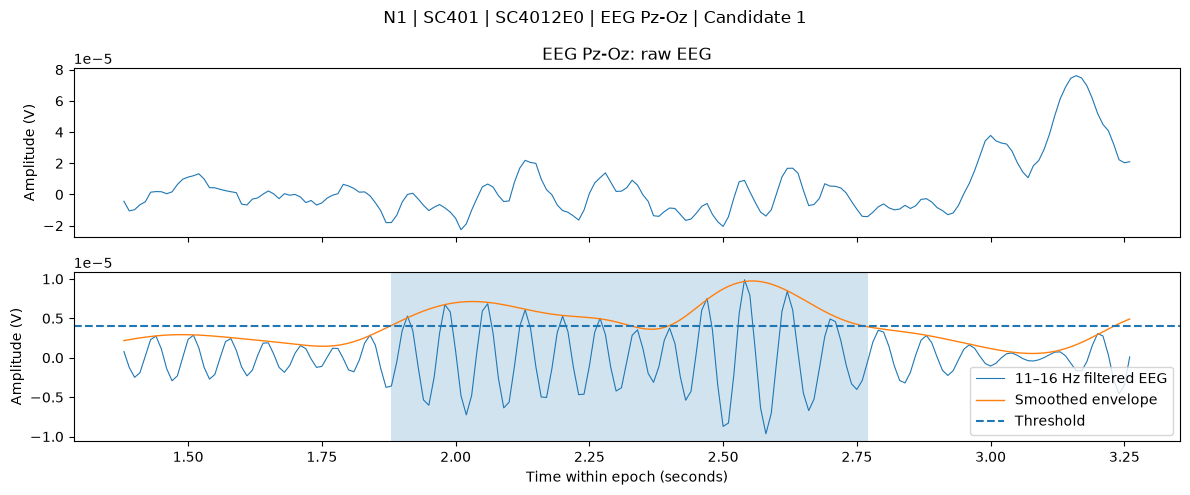

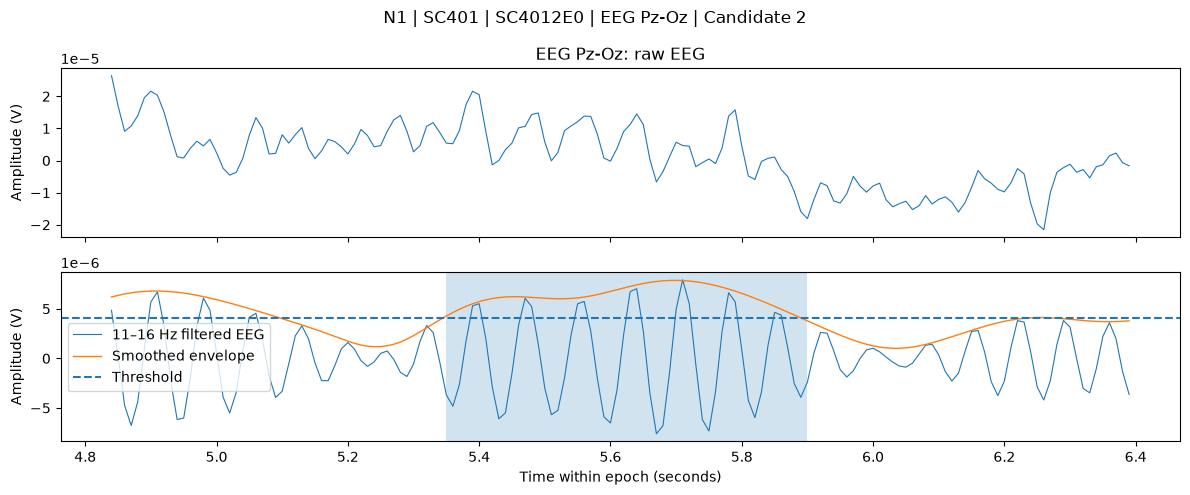

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


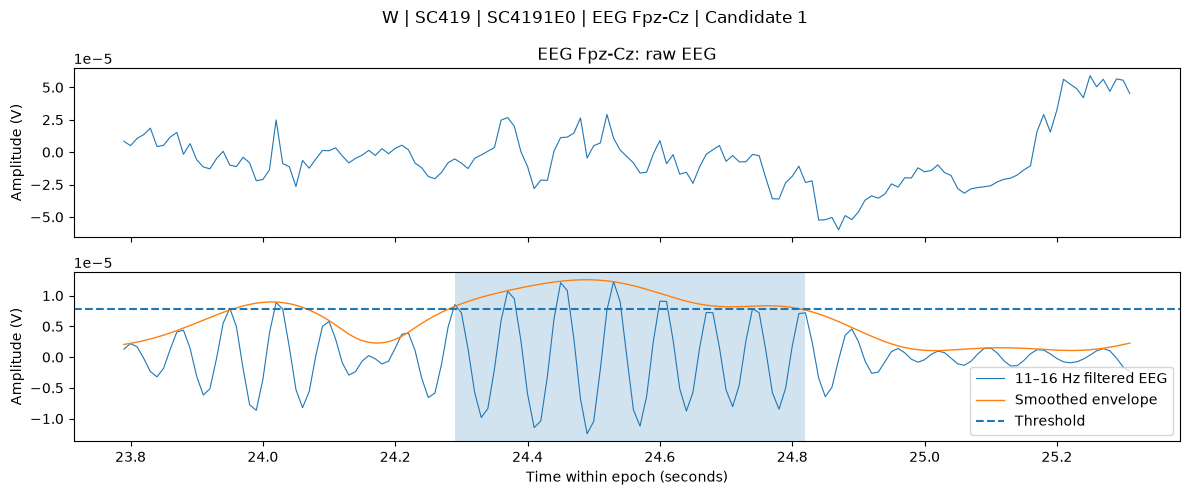

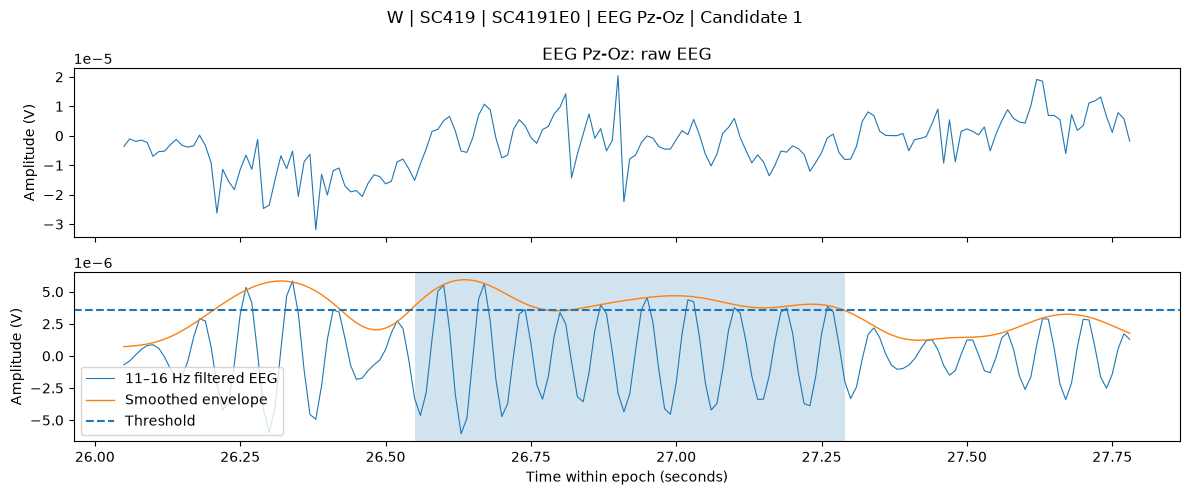

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


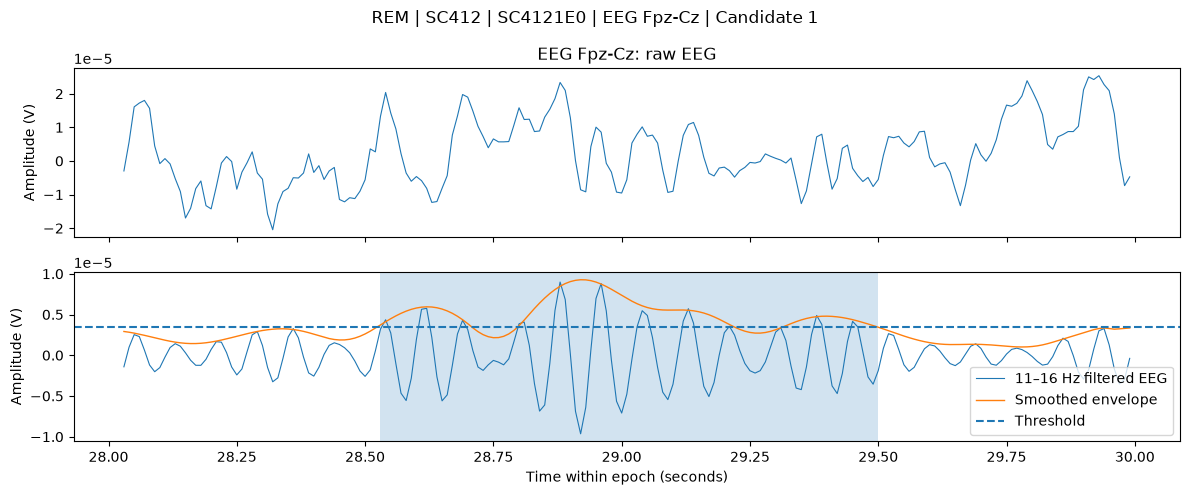

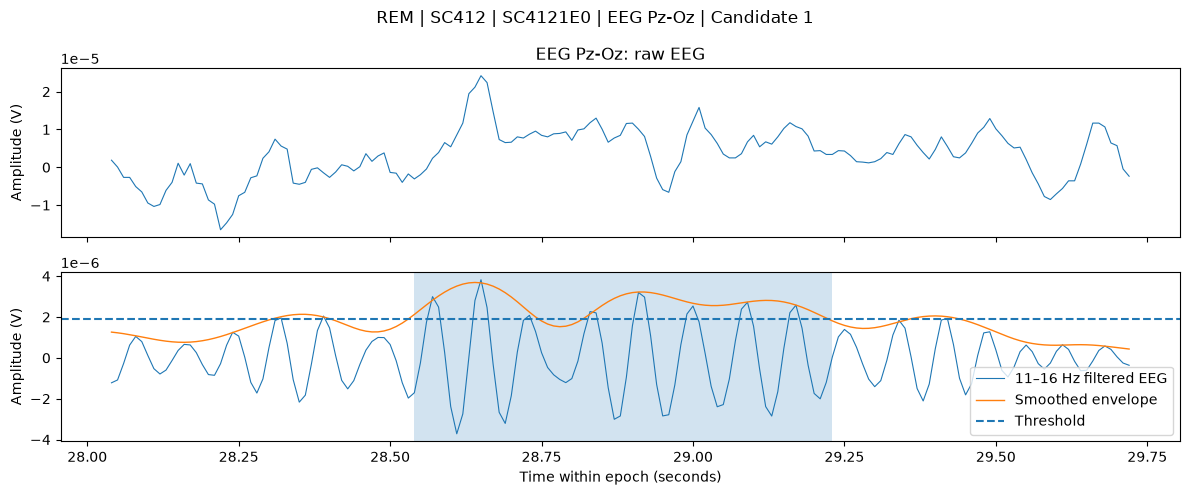

In [12]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

CHANNELS_TO_COMPARE = ["EEG Fpz-Cz", "EEG Pz-Oz"]

detected_epochs = chosen_df[chosen_df["n_candidates"] > 0].copy()

for _, epoch in detected_epochs.iterrows():
    psg_path, hypnogram_path = find_recording_pair(
        epoch["recording_id"]
    )

    raw = None
    try:
        raw = load_recording(psg_path, hypnogram_path)
        sfreq = raw.info["sfreq"]

        start_sample = int(round(epoch["start_sec"] * sfreq))
        end_sample = int(round(epoch["end_sec"] * sfreq))

        available_channels = [
            ch for ch in CHANNELS_TO_COMPARE if ch in raw.ch_names
        ]

        if not available_channels:
            print("Neither comparison channel is available.")
            continue

        signals = raw.get_data(
            picks=available_channels,
            start=start_sample,
            stop=end_sample
        )

        time = np.arange(signals.shape[1]) / sfreq

        for channel, signal in zip(available_channels, signals):
            events, filtered, envelope, threshold = (
                detect_spindles_in_epoch(signal, sfreq)
            )

            # Plot the strongest current candidate with 0.5 s context.
            if not events:
                print(
                    f"{epoch['stage']} | {epoch['recording_id']} | "
                    f"{channel}: no candidate in this channel"
                )
                continue

            for event_num, event in enumerate(events, start=1):
                left = max(
                    0, int((event["start_sec"] - 0.5) * sfreq)
                )
                right = min(
                    len(signal),
                    int((event["end_sec"] + 0.5) * sfreq)
                )

                fig, axes = plt.subplots(
                    2, 1, figsize=(12, 5), sharex=True
                )

                axes[0].plot(
                    time[left:right], signal[left:right],
                    linewidth=0.8
                )
                axes[0].set_title(f"{channel}: raw EEG")
                axes[0].set_ylabel("Amplitude (V)")

                axes[1].plot(
                    time[left:right], filtered[left:right],
                    linewidth=0.8, label="11–16 Hz filtered EEG"
                )
                axes[1].plot(
                    time[left:right], envelope[left:right],
                    linewidth=1, label="Smoothed envelope"
                )
                axes[1].axhline(
                    threshold, linestyle="--", label="Threshold"
                )
                axes[1].axvspan(
                    event["start_sec"], event["end_sec"], alpha=0.2
                )
                axes[1].set_xlabel("Time within epoch (seconds)")
                axes[1].set_ylabel("Amplitude (V)")
                axes[1].legend()

                fig.suptitle(
                    f"{epoch['stage']} | {epoch['subject_id']} | "
                    f"{epoch['recording_id']} | "
                    f"{channel} | Candidate {event_num}"
                )
                plt.tight_layout()
                plt.show()

    finally:
        if raw is not None:
            raw.close()


In [13]:

import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import uniform_filter1d

def detect_spindles_padded(signal, sfreq, pre_samples, epoch_samples,
                           threshold_sd=1.5, min_duration=0.5,
                           max_duration=2.0, merge_gap=0.1):

    signal = np.asarray(signal, dtype=float)

    sos = butter(
        4, [11, 16], btype="bandpass",
        fs=sfreq, output="sos"
    )
    filtered = sosfiltfilt(sos, signal)
    envelope = np.abs(hilbert(filtered))

    smooth_samples = max(1, int(round(0.1 * sfreq)))
    envelope = uniform_filter1d(envelope, size=smooth_samples)

    # Threshold is calculated from the original epoch only.
    epoch_envelope = envelope[
        pre_samples:pre_samples + epoch_samples
    ]
    threshold = epoch_envelope.mean() + threshold_sd * epoch_envelope.std()

    active = envelope > threshold
    max_gap_samples = int(round(merge_gap * sfreq))
    active_indices = np.flatnonzero(active)

    events = []
    if len(active_indices):
        groups = np.split(
            active_indices,
            np.where(np.diff(active_indices) > max_gap_samples + 1)[0] + 1
        )

        epoch_start = pre_samples
        epoch_end = pre_samples + epoch_samples

        for group in groups:
            start, end = int(group[0]), int(group[-1]) + 1
            duration = (end - start) / sfreq

            # Keep only complete candidates within the original epoch.
            if (
                epoch_start <= start < end <= epoch_end
                and min_duration <= duration <= max_duration
            ):
                events.append({
                    "start_sec": (start - epoch_start) / sfreq,
                    "end_sec": (end - epoch_start) / sfreq,
                    "duration_sec": duration,
                    "peak_envelope": float(envelope[start:end].max())
                })

    return events


# Compare the old detector and padded detector on the same sample.
comparison_rows = []
CHANNEL = "EEG Fpz-Cz"
PAD_SECONDS = 2

for _, epoch in sample_df.iterrows():
    psg_path, hypnogram_path = find_recording_pair(epoch["recording_id"])
    raw = load_recording(psg_path, hypnogram_path)

    try:
        sfreq = raw.info["sfreq"]
        if CHANNEL not in raw.ch_names:
            continue

        start = int(round(epoch["start_sec"] * sfreq))
        end = int(round(epoch["end_sec"] * sfreq))
        pad = int(round(PAD_SECONDS * sfreq))

        # Require the full 2-second context on both sides.
        if start < pad or end + pad > raw.n_times:
            continue

        signal_padded = raw.get_data(
            picks=[CHANNEL], start=start-pad, stop=end+pad
        )[0]
        signal_epoch = signal_padded[pad:pad + (end-start)]

        old_events, _, _, _ = detect_spindles_in_epoch(
            signal_epoch, sfreq
        )
        new_events = detect_spindles_padded(
            signal_padded, sfreq,
            pre_samples=pad,
            epoch_samples=end-start
        )

        comparison_rows.append({
            "subject_id": epoch["subject_id"],
            "recording_id": epoch["recording_id"],
            "epoch_index": epoch["epoch_index"],
            "stage": epoch["stage"],
            "old_count": len(old_events),
            "padded_count": len(new_events),
            "count_changed": len(old_events) != len(new_events)
        })
    finally:
        raw.close()

comparison_df = pd.DataFrame(comparison_rows)

print("Epochs compared:", len(comparison_df))
print("Epochs with changed candidate counts:",
      int(comparison_df["count_changed"].sum()))

print("\nCounts by stage:")
display(
    comparison_df.groupby("stage")[
        ["old_count", "padded_count", "count_changed"]
    ].agg({
        "old_count": "sum",
        "padded_count": "sum",
        "count_changed": "sum"
    }).sort_index()
)

print("\nEpochs whose candidate counts changed:")
display(
    comparison_df[comparison_df["count_changed"]].head(20)
)


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:2

Epochs compared: 112
Epochs with changed candidate counts: 0

Counts by stage:


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:2

,old_count,padded_count,count_changed
stage,,,
N1,25,25,0
N2,27,27,0
N3,9,9,0
REM,7,7,0
W,8,8,0



Epochs whose candidate counts changed:


,subject_id,recording_id,epoch_index,stage,old_count,padded_count,count_changed


In [14]:

# Re-detect candidates and measure their basic characteristics.
# Uses sample_df, find_recording_pair(), and detect_spindles_padded().

from scipy.signal import welch, find_peaks

rows = []
CHANNEL = "EEG Fpz-Cz"
PAD_SECONDS = 2

for _, epoch in sample_df.iterrows():
    psg_path, hypnogram_path = find_recording_pair(epoch["recording_id"])
    raw = load_recording(psg_path, hypnogram_path)

    try:
        sfreq = raw.info["sfreq"]
        if CHANNEL not in raw.ch_names:
            continue

        start = int(round(epoch["start_sec"] * sfreq))
        end = int(round(epoch["end_sec"] * sfreq))
        pad = int(round(PAD_SECONDS * sfreq))

        if start < pad or end + pad > raw.n_times:
            continue

        x = raw.get_data(
            picks=[CHANNEL], start=start-pad, stop=end+pad
        )[0]

        # Filter extended signal and compute its envelope.
        from scipy.signal import butter, sosfiltfilt
        from scipy.ndimage import uniform_filter1d

        sos = butter(4, [11, 16], btype="bandpass",
                     fs=sfreq, output="sos")
        filt = sosfiltfilt(sos, x)
        env = uniform_filter1d(np.abs(hilbert(filt)),
                               size=max(1, round(0.1 * sfreq)))

        epoch_env = env[pad:pad + (end-start)]
        threshold = epoch_env.mean() + 1.5 * epoch_env.std()
        active = env > threshold
        idx = np.flatnonzero(active)
        groups = (np.split(idx, np.where(np.diff(idx) > round(0.1*sfreq)+1)[0]+1)
                  if len(idx) else [])

        for group in groups:
            a, b = int(group[0]), int(group[-1])+1
            duration = (b-a)/sfreq

            if not (pad <= a < b <= pad+(end-start)
                    and 0.5 <= duration <= 2.0):
                continue

            segment = filt[a:b]
            freqs, power = welch(segment, fs=sfreq,
                                 nperseg=min(len(segment), 256))
            band = (freqs >= 11) & (freqs <= 16)
            dominant_frequency = (
                float(freqs[band][np.argmax(power[band])])
                if band.any() else np.nan
            )

            rows.append({
                "stage": epoch["stage"],
                "recording_id": epoch["recording_id"],
                "epoch_index": epoch["epoch_index"],
                "duration_sec": duration,
                "dominant_frequency_hz": dominant_frequency,
                "peak_envelope": float(env[a:b].max()),
                "envelope_cv": float(env[a:b].std() /
                                     (env[a:b].mean() + 1e-12))
            })
    finally:
        raw.close()

candidate_quality_df = pd.DataFrame(rows)

print("Candidates measured:", len(candidate_quality_df))
display(
    candidate_quality_df.groupby("stage").agg(
        candidates=("duration_sec", "size"),
        median_duration=("duration_sec", "median"),
        median_frequency=("dominant_frequency_hz", "median"),
        median_envelope_cv=("envelope_cv", "median")
    ).round(3)
)


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:2

Candidates measured: 76


d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: Runti

,candidates,median_duration,median_frequency,median_envelope_cv
stage,,,,
N1,25,0.59,12.963,0.207
N2,27,0.62,13.462,0.173
N3,9,0.54,13.793,0.171
REM,7,0.60,12.500,0.139
W,8,0.59,13.161,0.194


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


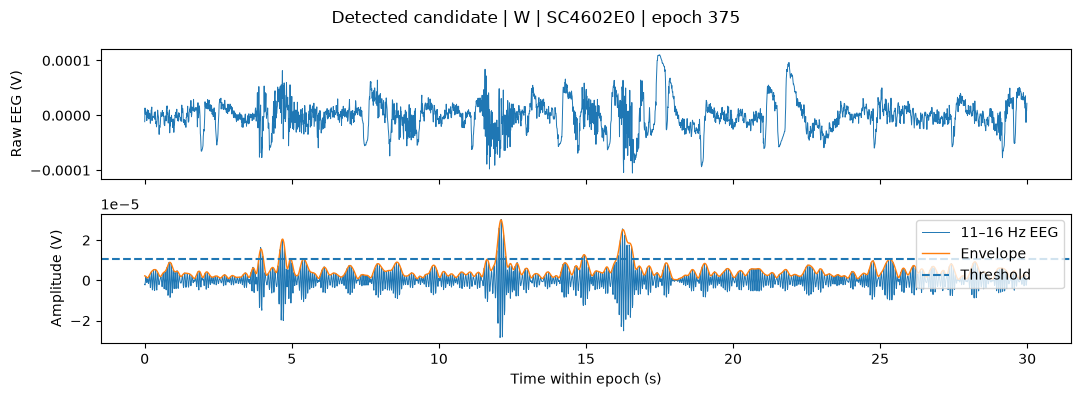

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


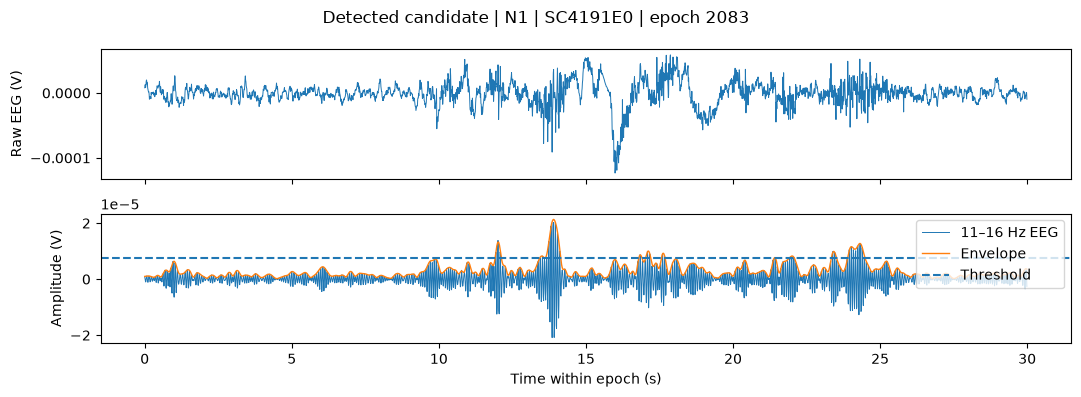

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


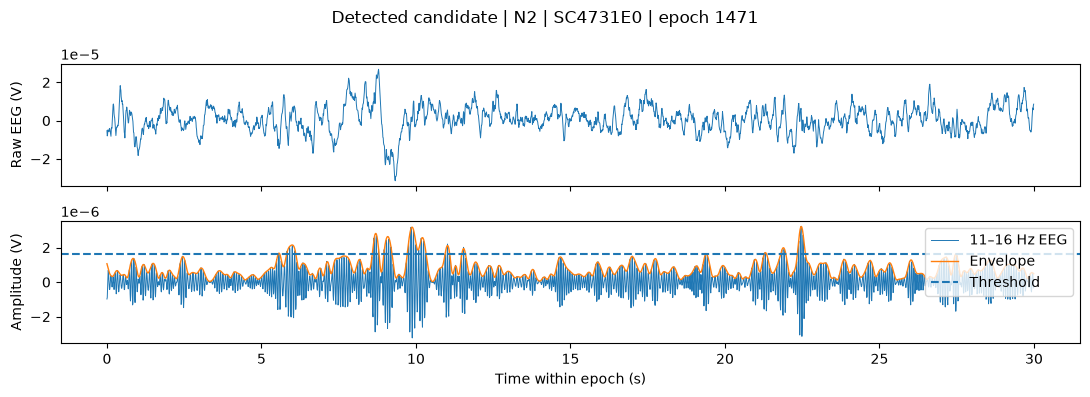

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(


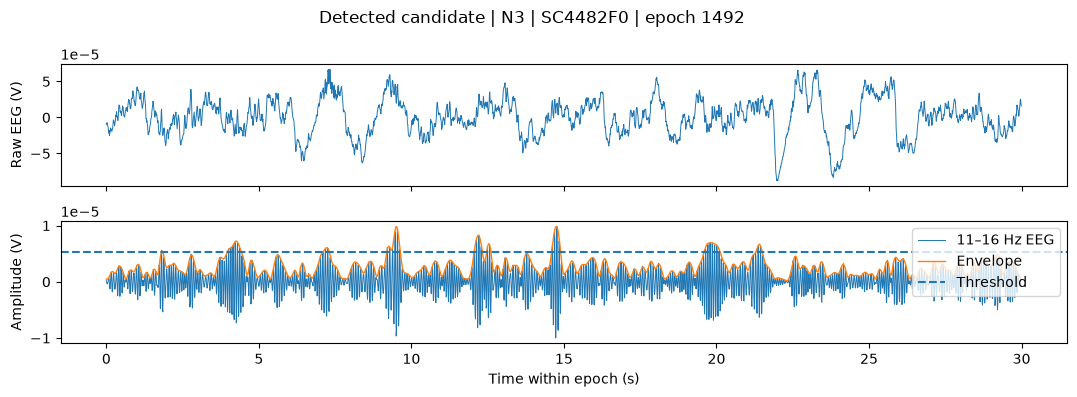

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


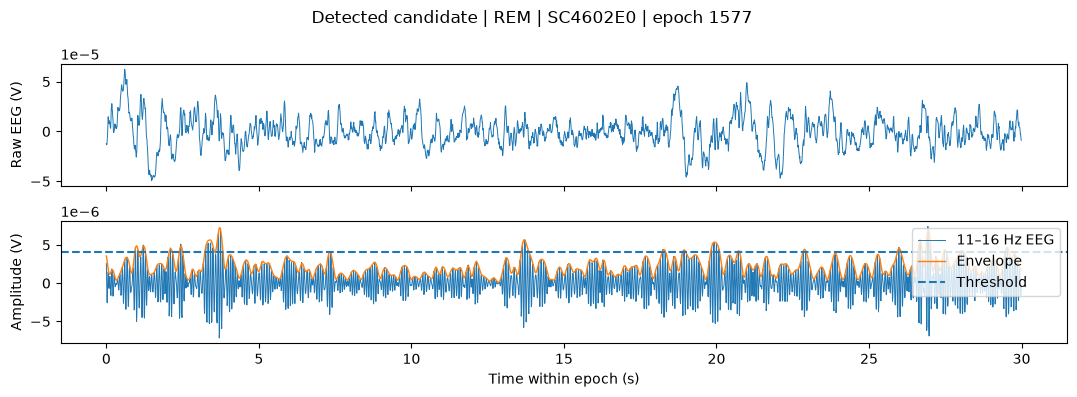

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


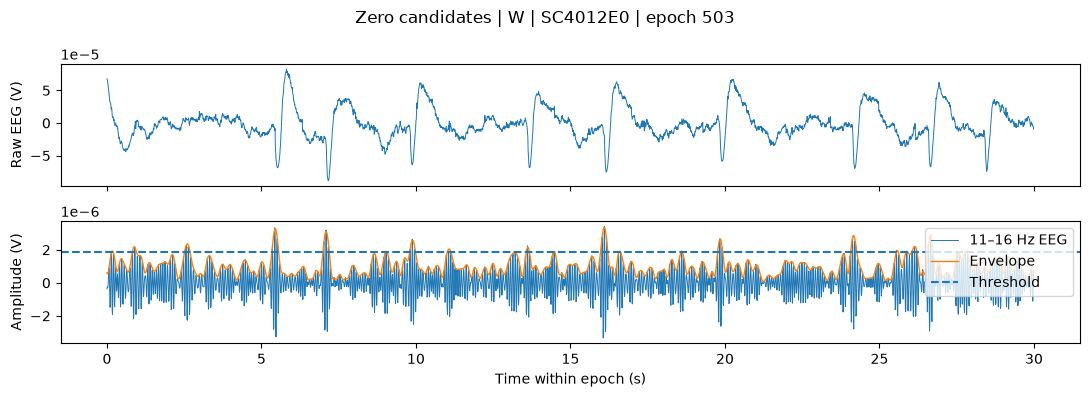

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


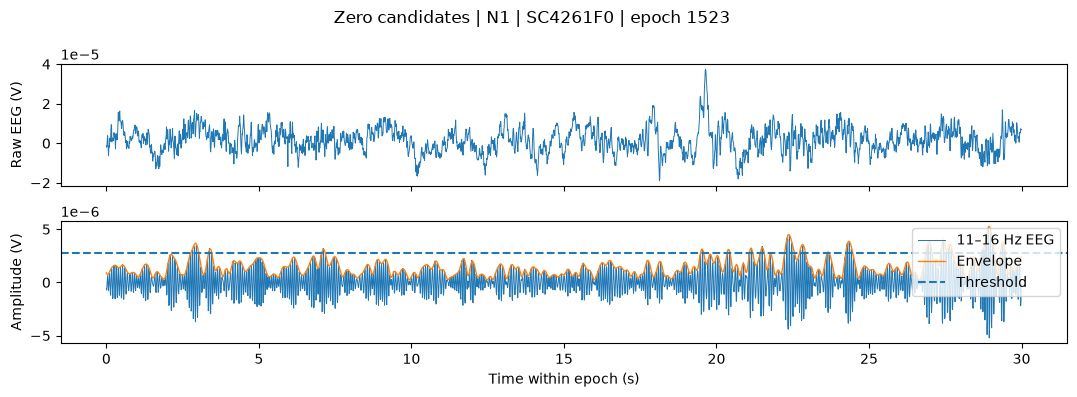

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


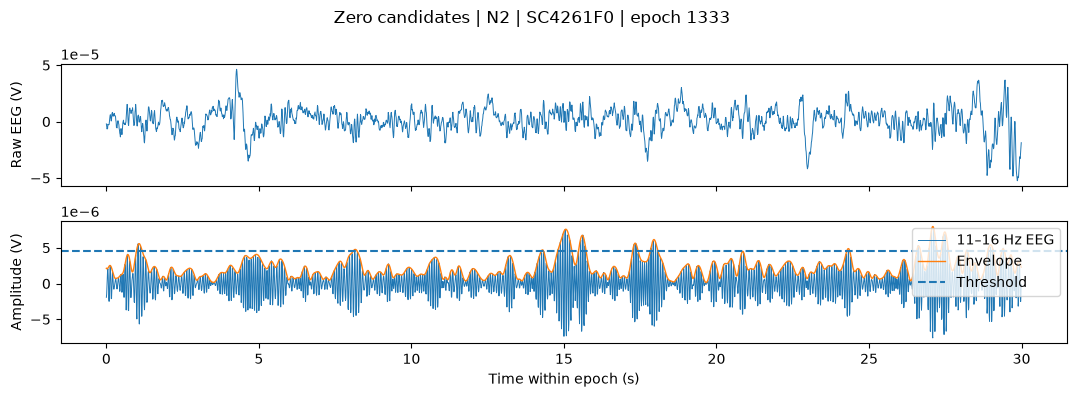

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


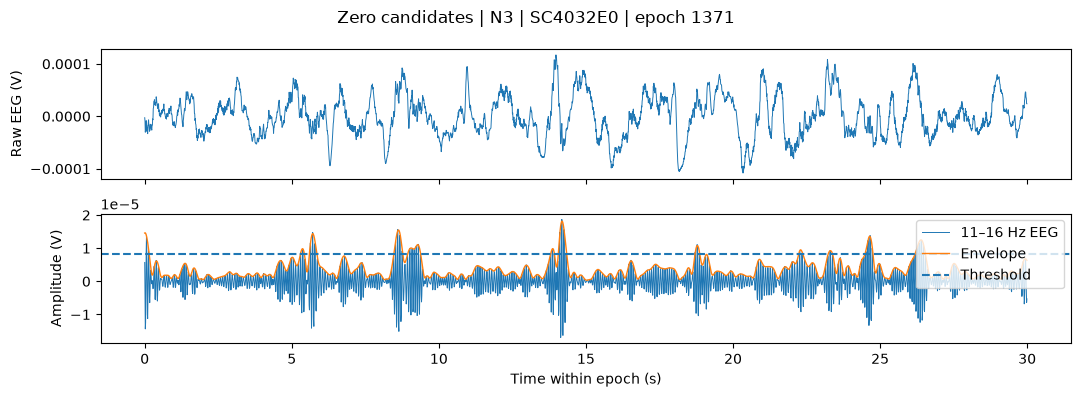

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


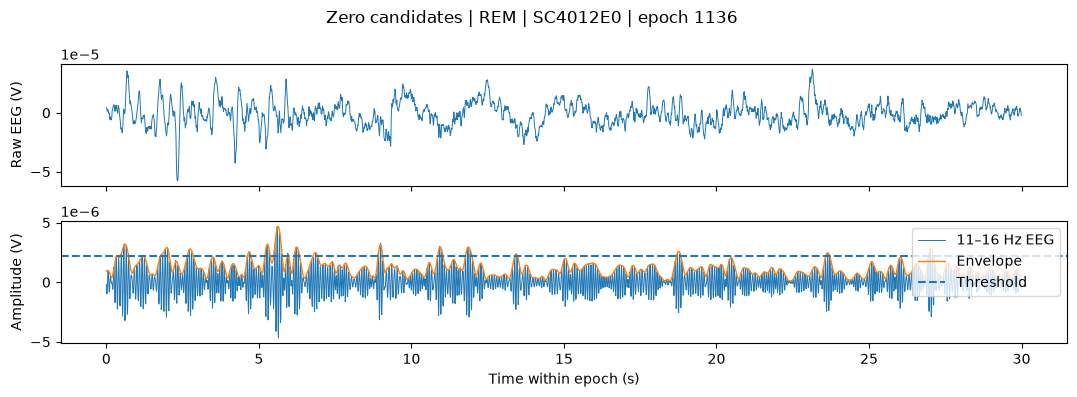

In [15]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import uniform_filter1d

review_items = []

# One detected candidate per stage, chosen near median candidate duration.
for stage in ["W", "N1", "N2", "N3", "REM"]:
    stage_candidates = candidate_quality_df[
        candidate_quality_df["stage"] == stage
    ]
    if not stage_candidates.empty:
        target_duration = stage_candidates["duration_sec"].median()
        selected = stage_candidates.iloc[
            (stage_candidates["duration_sec"] - target_duration)
            .abs().argsort().iloc[0]
        ]
        review_items.append({
            "stage": stage,
            "recording_id": selected["recording_id"],
            "epoch_index": int(selected["epoch_index"]),
            "kind": "Detected candidate",
        })

# One epoch with zero detections per stage, where available.
for stage in ["W", "N1", "N2", "N3", "REM"]:
    zero_epochs = sample_detection_df[
        (sample_detection_df["stage"] == stage) &
        (sample_detection_df["n_candidates"] == 0)
    ]
    if not zero_epochs.empty:
        selected = zero_epochs.iloc[0]
        review_items.append({
            "stage": stage,
            "recording_id": selected["recording_id"],
            "epoch_index": int(selected["epoch_index"]),
            "kind": "Zero candidates",
        })

for item in review_items:
    timing = sample_df[
        (sample_df["recording_id"] == item["recording_id"]) &
        (sample_df["epoch_index"] == item["epoch_index"])
    ]
    if timing.empty:
        continue

    epoch = timing.iloc[0]
    psg_path, hypnogram_path = find_recording_pair(item["recording_id"])
    raw = load_recording(psg_path, hypnogram_path)

    try:
        sfreq = raw.info["sfreq"]
        start = int(round(epoch["start_sec"] * sfreq))
        end = int(round(epoch["end_sec"] * sfreq))
        pad = int(round(2 * sfreq))

        if start < pad or end + pad > raw.n_times:
            continue

        x = raw.get_data(
            picks=["EEG Fpz-Cz"], start=start-pad, stop=end+pad
        )[0]

        sos = butter(4, [11, 16], btype="bandpass",
                     fs=sfreq, output="sos")
        filtered = sosfiltfilt(sos, x)
        envelope = uniform_filter1d(
            np.abs(hilbert(filtered)),
            size=max(1, round(0.1 * sfreq))
        )

        a, b = pad, pad + (end-start)
        env_epoch = envelope[a:b]
        threshold = env_epoch.mean() + 1.5 * env_epoch.std()
        t = np.arange(end-start) / sfreq

        fig, axes = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
        axes[0].plot(t, x[a:b], linewidth=0.7)
        axes[0].set_ylabel("Raw EEG (V)")

        axes[1].plot(t, filtered[a:b], linewidth=0.7,
                     label="11–16 Hz EEG")
        axes[1].plot(t, env_epoch, linewidth=1,
                     label="Envelope")
        axes[1].axhline(threshold, linestyle="--",
                        label="Threshold")
        axes[1].set_xlabel("Time within epoch (s)")
        axes[1].set_ylabel("Amplitude (V)")
        axes[1].legend(loc="upper right")

        fig.suptitle(
            f"{item['kind']} | {item['stage']} | "
            f"{item['recording_id']} | epoch {item['epoch_index']}"
        )
        plt.tight_layout()
        plt.show()
    finally:
        raw.close()


In [17]:

import numpy as np
from scipy.signal import find_peaks

def characterize_spindle_candidate(filtered, envelope, start, end, sfreq):
    """
    Describe a detected candidate without changing detection rules.

    start/end are sample indices in the filtered signal.
    """
    segment = np.asarray(filtered[start:end], dtype=float)
    env = np.asarray(envelope[start:end], dtype=float)

    if len(segment) < 3 or len(env) < 3:
        return None

    duration = len(segment) / sfreq
    peak_idx = int(np.argmax(env))
    peak_amplitude = float(env[peak_idx])
    mean_amplitude = float(np.mean(env))

    # Envelope peak prominence: distinguish a peak from its surroundings.
    peaks, properties = find_peaks(env, prominence=0)
    if len(peaks):
        nearest_peak = peaks[np.argmin(np.abs(peaks - peak_idx))]
        prominence = float(
            properties["prominences"][
                np.argmin(np.abs(peaks - peak_idx))
            ]
        )
    else:
        prominence = 0.0

    # Compare average envelope amplitude in the first and last thirds.
    third = max(1, len(env) // 3)
    early_mean = float(np.mean(env[:third]))
    middle_mean = float(np.mean(env[third:2*third]))
    late_mean = float(np.mean(env[2*third:]))

    # Number of oscillation cycles, estimated from filtered-signal peaks.
    peaks_signal, _ = find_peaks(segment)
    cycle_count = max(0, len(peaks_signal) - 1)
    cycle_rate_hz = cycle_count / duration if duration > 0 else np.nan

    # Regularity of intervals between consecutive positive peaks.
    if len(peaks_signal) >= 3:
        intervals = np.diff(peaks_signal) / sfreq
        interval_cv = float(
            np.std(intervals) / (np.mean(intervals) + 1e-12)
        )
    else:
        interval_cv = np.nan

    # Normalized envelope variability within the candidate.
    envelope_cv = float(
        np.std(env) / (np.mean(env) + 1e-12)
    )

    # Descriptive only: not a validated spindle score.
    return {
        "duration_sec": duration,
        "peak_envelope": peak_amplitude,
        "mean_envelope": mean_amplitude,
        "peak_prominence": prominence,
        "early_envelope_mean": early_mean,
        "middle_envelope_mean": middle_mean,
        "late_envelope_mean": late_mean,
        "cycle_count_estimate": cycle_count,
        "cycle_rate_hz_estimate": cycle_rate_hz,
        "peak_interval_cv": interval_cv,
        "envelope_cv": envelope_cv,
    }


In [20]:

import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import uniform_filter1d

morphology_rows = []

CHANNEL = "EEG Fpz-Cz"
PAD_SECONDS = 2

for _, epoch in sample_df.iterrows():
    psg_path, hypnogram_path = find_recording_pair(epoch["recording_id"])
    raw = load_recording(psg_path, hypnogram_path)

    try:
        sfreq = raw.info["sfreq"]

        if CHANNEL not in raw.ch_names:
            continue

        start = int(round(epoch["start_sec"] * sfreq))
        end = int(round(epoch["end_sec"] * sfreq))
        pad = int(round(PAD_SECONDS * sfreq))

        if start < pad or end + pad > raw.n_times:
            continue

        signal = raw.get_data(
            picks=[CHANNEL], start=start-pad, stop=end+pad
        )[0]

        sos = butter(
            4, [11, 16], btype="bandpass",
            fs=sfreq, output="sos"
        )
        filtered = sosfiltfilt(sos, signal)
        envelope = uniform_filter1d(
            np.abs(hilbert(filtered)),
            size=max(1, int(round(0.1 * sfreq)))
        )

        epoch_start = pad
        epoch_end = pad + (end-start)
        epoch_envelope = envelope[epoch_start:epoch_end]
        threshold = epoch_envelope.mean() + 1.5 * epoch_envelope.std()

        active = envelope > threshold
        indices = np.flatnonzero(active)
        max_gap = int(round(0.1 * sfreq))

        groups = (
            np.split(indices, np.where(np.diff(indices) > max_gap + 1)[0] + 1)
            if len(indices) else []
        )

        for group in groups:
            a, b = int(group[0]), int(group[-1]) + 1
            duration = (b-a) / sfreq

            # Preserve the original detector's duration and epoch rules.
            if not (
                epoch_start <= a < b <= epoch_end
                and 0.5 <= duration <= 2.0
            ):
                continue

            metrics = characterize_spindle_candidate(
                filtered, envelope, a, b, sfreq
            )

            if metrics is not None:
                morphology_rows.append({
                    "stage": epoch["stage"],
                    "subject_id": epoch["subject_id"],
                    "recording_id": epoch["recording_id"],
                    "epoch_index": int(epoch["epoch_index"]),
                    **metrics
                })
    finally:
        raw.close()

morphology_df = pd.DataFrame(morphology_rows)

print("Candidates characterized:", len(morphology_df))

display(
    morphology_df.groupby("stage").agg(
        candidates=("duration_sec", "size"),
        median_duration=("duration_sec", "median"),
        median_prominence=("peak_prominence", "median"),
        median_cycle_rate=("cycle_rate_hz_estimate", "median"),
        median_peak_interval_cv=("peak_interval_cv", "median"),
        median_envelope_cv=("envelope_cv", "median")
    ).round(3)
)


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:2

Candidates characterized: 76


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:2

,candidates,median_duration,median_prominence,median_cycle_rate,median_peak_interval_cv,median_envelope_cv
stage,,,,,,
N1,25,0.59,0.0,11.429,0.067,0.207
N2,27,0.62,0.0,11.538,0.066,0.173
N3,9,0.54,0.0,11.111,0.064,0.171
REM,7,0.60,0.0,10.000,0.049,0.139
W,8,0.59,0.0,11.206,0.074,0.194


In [19]:

# Measure prominence against the surrounding envelope, not only
# against the threshold-defined candidate segment.

from scipy.signal import find_peaks

context_seconds = 0.5
context = int(round(context_seconds * sfreq))

left = max(0, start - context)
right = min(len(envelope), end + context)

context_envelope = envelope[left:right]
context_peaks, context_properties = find_peaks(
    context_envelope, prominence=0
)

if len(context_peaks):
    candidate_peak_local = int(np.argmax(envelope[start:end])) + start
    candidate_peak_context = candidate_peak_local - left

    nearest_idx = int(np.argmin(
        np.abs(context_peaks - candidate_peak_context)
    ))

    peak_prominence = float(
        context_properties["prominences"][nearest_idx]
    )
else:
    peak_prominence = 0.0


In [21]:

import numpy as np
import pandas as pd
from scipy.signal import find_peaks

# Recalculate prominence using 0.5 seconds of envelope context
# on each side of every candidate.
prominence_rows = []

for _, epoch in sample_df.iterrows():
    psg_path, hypnogram_path = find_recording_pair(epoch["recording_id"])
    raw = load_recording(psg_path, hypnogram_path)

    try:
        sfreq = raw.info["sfreq"]
        channel = "EEG Fpz-Cz"
        start = int(round(epoch["start_sec"] * sfreq))
        end = int(round(epoch["end_sec"] * sfreq))
        pad = int(round(2 * sfreq))

        if channel not in raw.ch_names or start < pad or end + pad > raw.n_times:
            continue

        signal = raw.get_data(
            picks=[channel], start=start-pad, stop=end+pad
        )[0]

        from scipy.signal import butter, sosfiltfilt, hilbert
        from scipy.ndimage import uniform_filter1d

        sos = butter(4, [11, 16], btype="bandpass",
                     fs=sfreq, output="sos")
        filtered = sosfiltfilt(sos, signal)
        envelope = uniform_filter1d(
            np.abs(hilbert(filtered)),
            size=max(1, round(0.1 * sfreq))
        )

        ep_start = pad
        ep_end = pad + (end-start)
        ep_env = envelope[ep_start:ep_end]
        threshold = ep_env.mean() + 1.5 * ep_env.std()

        active = np.flatnonzero(envelope > threshold)
        gap = int(round(0.1 * sfreq))
        groups = (
            np.split(active, np.where(np.diff(active) > gap+1)[0]+1)
            if len(active) else []
        )

        for group in groups:
            a, b = int(group[0]), int(group[-1])+1
            duration = (b-a)/sfreq
            if not (ep_start <= a < b <= ep_end and 0.5 <= duration <= 2.0):
                continue

            # Context around candidate; candidate indices remain absolute.
            ctx = int(round(0.5 * sfreq))
            left = max(0, a-ctx)
            right = min(len(envelope), b+ctx)
            local_env = envelope[left:right]

            peaks, props = find_peaks(local_env, prominence=0)
            candidate_peak = int(a + np.argmax(envelope[a:b]))
            local_peak = candidate_peak-left

            if len(peaks):
                nearest = int(np.argmin(np.abs(peaks-local_peak)))
                prom = float(props["prominences"][nearest])
            else:
                prom = 0.0

            prominence_rows.append({
                "stage": epoch["stage"],
                "recording_id": epoch["recording_id"],
                "epoch_index": int(epoch["epoch_index"]),
                "duration_sec": duration,
                "peak_prominence": prom,
                "peak_envelope": float(envelope[a:b].max())
            })
    finally:
        raw.close()

prominence_df = pd.DataFrame(prominence_rows)

print("Candidates:", len(prominence_df))
display(
    prominence_df.groupby("stage").agg(
        candidates=("peak_prominence", "size"),
        median_prominence=("peak_prominence", "median"),
        median_peak_envelope=("peak_envelope", "median")
    ).round(8)
)


d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:2

Candidates: 76


,candidates,median_prominence,median_peak_envelope
stage,,,
N1,25,0.000007,0.000010
N2,27,0.000010,0.000011
N3,9,0.000005,0.000007
REM,7,0.000006,0.000007
W,8,0.000012,0.000014


In [22]:

import numpy as np
import pandas as pd

# Aggregate candidate-level measurements into epoch-level features.
spindle_features = (
    prominence_df.groupby(
        ["recording_id", "epoch_index"], as_index=False
    )
    .agg(
        spindle_candidate_count=("peak_prominence", "size"),
        spindle_total_duration_sec=("duration_sec", "sum"),
        spindle_mean_duration_sec=("duration_sec", "mean"),
        spindle_max_duration_sec=("duration_sec", "max"),
        spindle_mean_prominence=("peak_prominence", "mean"),
    )
)

# Include every sampled epoch, including those with no candidates.
spindle_features = sample_df[
    ["subject_id", "recording_id", "epoch_index", "stage",
     "start_sec", "end_sec"]
].merge(
    spindle_features,
    on=["recording_id", "epoch_index"],
    how="left",
    validate="one_to_one"
)

count_col = "spindle_candidate_count"
feature_cols = [
    "spindle_candidate_count",
    "spindle_total_duration_sec",
    "spindle_mean_duration_sec",
    "spindle_max_duration_sec",
    "spindle_mean_prominence",
]

spindle_features[feature_cols] = (
    spindle_features[feature_cols].fillna(0)
)

spindle_features["spindle_candidate_density"] = (
    spindle_features["spindle_candidate_count"] / 30.0
)

print("Epoch rows:", len(spindle_features))
print("Unique recordings:", spindle_features["recording_id"].nunique())
print("Missing feature values:",
      int(spindle_features[feature_cols + ["spindle_candidate_density"]]
          .isna().sum().sum()))

display(
    spindle_features.groupby("stage").agg(
        epochs=("epoch_index", "size"),
        mean_candidate_count=("spindle_candidate_count", "mean"),
        median_total_duration=("spindle_total_duration_sec", "median"),
        median_max_duration=("spindle_max_duration_sec", "median"),
        median_candidate_density=("spindle_candidate_density", "median"),
    ).round(4)
)


Epoch rows: 112
Unique recordings: 23
Missing feature values: 0


,epochs,mean_candidate_count,median_total_duration,median_max_duration,median_candidate_density
stage,,,,,
N1,23,1.0870,0.72,0.56,0.0333
N2,23,1.1739,0.61,0.61,0.0333
N3,20,0.4500,0.00,0.00,0.0000
REM,23,0.3043,0.00,0.00,0.0000
W,23,0.3478,0.00,0.00,0.0000


In [23]:

# 1. Confirm one row per epoch.
assert not spindle_features.duplicated(
    ["recording_id", "epoch_index"]
).any()

# 2. Confirm all 112 sampled epochs are retained.
assert len(spindle_features) == len(sample_df)

# 3. Confirm feature values are finite and non-negative.
feature_cols = [
    "spindle_candidate_count",
    "spindle_total_duration_sec",
    "spindle_mean_duration_sec",
    "spindle_max_duration_sec",
    "spindle_mean_prominence",
    "spindle_candidate_density",
]

assert np.isfinite(spindle_features[feature_cols].to_numpy()).all()
assert (spindle_features[feature_cols] >= 0).all().all()

# 4. Check zero-candidate epochs.
zero_check = spindle_features[
    spindle_features["spindle_candidate_count"] == 0
]

assert (
    zero_check[
        ["spindle_total_duration_sec",
         "spindle_mean_duration_sec",
         "spindle_max_duration_sec",
         "spindle_mean_prominence"]
    ] == 0
).all().all()

print("All sanity checks passed.")
print("Total epochs:", len(spindle_features))
print("Zero-candidate epochs:", len(zero_check))
print("Candidate-containing epochs:",
      int((spindle_features["spindle_candidate_count"] > 0).sum()))

display(
    spindle_features.groupby("stage")[
        ["spindle_candidate_count", "spindle_total_duration_sec"]
    ].agg(["min", "median", "max"]).round(4)
)


All sanity checks passed.
Total epochs: 112
Zero-candidate epochs: 58
Candidate-containing epochs: 54


spindle_candidate_count             spindle_total_duration_sec         \
                          min median  max                        min median   
stage                                                                         
N1                        0.0    1.0  3.0                        0.0   0.72   
N2                        0.0    1.0  3.0                        0.0   0.61   
N3                        0.0    0.0  2.0                        0.0   0.00   
REM                       0.0    0.0  2.0                        0.0   0.00   
W                         0.0    0.0  2.0                        0.0   0.00   

             
        max  
stage        
N1     1.91  
N2     2.41  
N3     1.26  
REM    1.15  
W      2.36

In [24]:

import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Match the same sampled epochs for both models.
data = spindle_features[
    spindle_features["stage"].isin(["N1", "N2"])
].copy()

baseline_cols = [
    "spindle_candidate_count"  # placeholder replaced below
]

# Join existing V2 signal features using recording + epoch keys.
# Update v2_df below if your combined V2 DataFrame has a different name.
v2_df = pd.read_csv(r"data\processed\sleep_epochs_v2.csv")

keys = ["recording_id", "epoch_index"]
if not set(keys).issubset(v2_df.columns):
    raise ValueError("V2 dataset must contain recording_id and epoch_index.")

# Keep only the existing numeric model features, excluding identifiers/labels.
excluded = {
    "subject_id", "recording_id", "epoch_index",
    "stage", "start_sec", "end_sec"
}
numeric_cols = [
    c for c in v2_df.select_dtypes(include=np.number).columns
    if c not in excluded
]

joined = data.merge(
    v2_df[keys + numeric_cols],
    on=keys,
    how="inner",
    validate="one_to_one"
)

spindle_cols = [
    "spindle_candidate_count",
    "spindle_total_duration_sec",
    "spindle_mean_duration_sec",
    "spindle_max_duration_sec",
    "spindle_mean_prominence",
]

# Avoid the redundant density feature: count / 30 seconds.
spindle_cols = [c for c in spindle_cols if c in joined.columns]
X_base = joined[numeric_cols]
X_spindle = joined[numeric_cols + spindle_cols]
y = joined["stage"]
groups = joined["subject_id"]

logo = LeaveOneGroupOut()
results = []

for name, X in [
    ("V2 baseline", X_base),
    ("V2 + spindle candidates", X_spindle)
]:
    y_true, y_pred = [], []

    for train_idx, test_idx in logo.split(X, y, groups):
        model = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(max_iter=2000, class_weight="balanced")
        )
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        y_pred.extend(model.predict(X.iloc[test_idx]))
        y_true.extend(y.iloc[test_idx])

    results.append({
        "model": name,
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro")
    })

display(pd.DataFrame(results).round(4))


FileNotFoundError: [Errno 2] No such file or directory: 'data\\processed\\sleep_epochs_v2.csv'